# Proyek Analisis Data: Air Quality Dataset
- **Nama:** M Fahril Luthfi
- **Email:** mfahrilluthfi@gmail.com
- **ID Dicoding:** m_fahril_luthfit7lm

## Pendahuluan

Proyek ini menganalisis **Air Quality Dataset**: data kualitas udara per jam dari **12 stasiun pemantau** di Beijing, Tiongkok, periode **1 Maret 2013 – 28 Februari 2017** (35.064 jam per stasiun). Setiap baris memuat konsentrasi polutan (PM2.5, PM10, SO2, NO2, CO, O3) dan kondisi cuaca (suhu, tekanan, titik embun, hujan, arah dan kecepatan angin).

Analisis berfokus pada **PM2.5** (partikel halus, polutan utama pada data ini) dan menjawab tiga hal: **stasiun mana yang paling tercemar (BQ1)**, **kapan pencemaran memburuk dan bagaimana tren tahunannya (BQ2)**, serta **bagaimana kondisi cuaca berhubungan dengan PM2.5 (BQ3)**. Sebagai analisis lanjutan, hari-hari dikelompokkan ke dalam kategori kualitas udara (manual grouping/binning, tanpa machine learning).

**Alur:** Business Questions → Data Wrangling (Gathering, Assessing, Cleaning) → EDA → Visualization & Explanatory Analysis → Analisis Lanjutan → Conclusion & Recommendation.

**Prinsip kerja:** seluruh angka dihitung langsung oleh Python dari dataset. Dua acuan di luar dataset dipakai sebagai ambang interpretasi, bukan sebagai data: batas harian **75 µg/m³** dan batas tahunan **35 µg/m³** untuk PM2.5 (Standar Kualitas Udara Ambien China GB 3095-2012, Grade II), serta batas kategori kualitas udara harian dari skema HJ 633-2012 (dijelaskan pada bagian Analisis Lanjutan).

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan bisnis final (dipilih berdasarkan hasil pemeriksaan dataset)**

Dataset memuat 12 stasiun dengan rentang waktu identik dan tanpa celah jam, sehingga perbandingan antar stasiun, antar musim, dan antar kondisi cuaca dapat dijawab langsung. Ukuran dasar yang dipakai adalah **rata-rata PM2.5 harian** per stasiun (hari dihitung hanya jika memiliki minimal 18 jam data valid; alasannya dibuktikan pada tahap Assessing). Ketiga pertanyaan saling melengkapi: **di mana (BQ1)**, **kapan (BQ2)**, dan **dalam kondisi cuaca apa (BQ3)** pencemaran memburuk.

- **Business Question 1 (Perbandingan Kualitas Udara Antar Stasiun):** Stasiun pemantau mana yang memiliki rata-rata PM2.5 harian tertinggi dan terendah di antara 12 stasiun selama 1 Maret 2013 – 28 Februari 2017, berapa selisihnya, dan berapa persen hari yang melampaui batas harian 75 µg/m³ di setiap stasiun, sehingga tim pemantau kualitas udara dapat memprioritaskan stasiun/wilayah untuk pengendalian dan peringatan dini?
- **Business Question 2 (Pola Musiman dan Tren Tahunan PM2.5):** Bagaimana pola bulanan dan musiman rata-rata PM2.5 harian selama 1 Maret 2013 – 28 Februari 2017, bulan dan musim mana yang terburuk, dan bagaimana perubahan rata-rata antar periode tahunan (Maret–Februari), sehingga tim dapat menjadwalkan kesiapsiagaan polusi dan mengevaluasi tren?
- **Business Question 3 (Pengaruh Kondisi Cuaca (Angin, Hujan, Arah Angin) terhadap PM2.5):** Bagaimana hubungan kecepatan angin, hujan, dan arah angin dengan PM2.5 harian selama 1 Maret 2013 – 28 Februari 2017, dan berapa persen lebih rendah PM2.5 pada hari berangin (> 3 m/s) dibanding hari tenang (<= 1 m/s), sehingga prakiraan cuaca dapat dipakai untuk peringatan dini polusi?

**Pengecekan SMART**

| Elemen | BQ1 | BQ2 | BQ3 |
|---|---|---|---|
| Specific | PM2.5 harian per stasiun | PM2.5 harian per bulan, musim, dan periode tahunan | PM2.5 harian menurut angin, hujan, dan arah angin |
| Measurable | Rata-rata, selisih, % hari > 75 µg/m³ | Rata-rata per bulan/musim/periode, % perubahan | Rata-rata per kelas angin, % selisih, korelasi |
| Action-Oriented | Prioritas stasiun/wilayah untuk pengendalian | Jadwal kesiapsiagaan dan evaluasi tren | Dasar peringatan dini berbasis prakiraan angin |
| Relevant | Pemantauan kualitas udara | Perencanaan pengendalian polusi | Prediksi hari berisiko tinggi |
| Time-bound | 1 Mar 2013 – 28 Feb 2017 | 1 Mar 2013 – 28 Feb 2017 | 1 Mar 2013 – 28 Feb 2017 |

## Import Semua Packages/Library yang Digunakan

**Tujuan:** memuat seluruh library di satu tempat agar notebook dapat dijalankan dari atas ke bawah.
- `glob`, `os`: membaca 12 file CSV stasiun
- `pandas`, `numpy`: manipulasi dan agregasi data
- `matplotlib`, `seaborn`: visualisasi

In [1]:
import glob
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

def rank_corr(a, b):
    # Korelasi Spearman = korelasi Pearson pada peringkat (tidak memerlukan SciPy)
    return a.rank().corr(b.rank())

## Data Wrangling

### Gathering Data

**Tujuan:** memuat seluruh file stasiun dan menggabungkannya menjadi satu DataFrame, lalu memastikan struktur semua file seragam.
**Proses:** membaca 12 file `PRSA_Data_*.csv` (satu file per stasiun) dengan path relatif `data/`, memeriksa bahwa kolomnya identik, lalu menggabungkannya dengan `pd.concat`. Kolom `station` sudah ada di setiap file sehingga data tetap dapat dibedakan per stasiun, dan penggabungan tidak membutuhkan kunci join.

#### Load air_df (gabungan 12 stasiun)

In [2]:
# Folder data (path relatif, portable). Fallback: file berada di folder yang sama dengan notebook (mis. Colab).
DATA_DIR = 'data' if os.path.isdir('data') else '.'
files = sorted(glob.glob(os.path.join(DATA_DIR, 'PRSA_Data_*.csv')))
if len(files) != 12:
    raise FileNotFoundError(f'Ditemukan {len(files)} file PRSA_Data_*.csv di {DATA_DIR}/ (seharusnya 12). Letakkan semua file CSV di folder data/.')

frames = [pd.read_csv(f) for f in files]
air_df = pd.concat(frames, ignore_index=True)

print(f'Jumlah file CSV (stasiun): {len(files)}')
print(f'Ukuran gabungan          : {air_df.shape[0]:,} baris x {air_df.shape[1]} kolom')
print('Kolom identik di semua file:', len({tuple(f.columns) for f in frames}) == 1)
air_df.groupby('station').size().to_frame('jumlah_baris')

Jumlah file CSV (stasiun): 12
Ukuran gabungan          : 420,768 baris x 18 kolom
Kolom identik di semua file: True


,jumlah_baris
station,
Aotizhongxin,35064
Changping,35064
Dingling,35064
Dongsi,35064
Guanyuan,35064
Gucheng,35064
Huairou,35064
Nongzhanguan,35064
Shunyi,35064


In [3]:
air_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.00,4.00,4.00,7.00,300.00,77.00,-0.70,"1,023.00",-18.80,0.00,NNW,4.40,Aotizhongxin
1,2,2013,3,1,1,8.00,8.00,4.00,7.00,300.00,77.00,-1.10,"1,023.20",-18.20,0.00,N,4.70,Aotizhongxin
2,3,2013,3,1,2,7.00,7.00,5.00,10.00,300.00,73.00,-1.10,"1,023.50",-18.20,0.00,NNW,5.60,Aotizhongxin
3,4,2013,3,1,3,6.00,6.00,11.00,11.00,300.00,72.00,-1.40,"1,024.50",-19.40,0.00,NW,3.10,Aotizhongxin
4,5,2013,3,1,4,3.00,3.00,12.00,12.00,300.00,72.00,-2.00,"1,025.20",-19.50,0.00,N,2.00,Aotizhongxin


In [4]:
print('Daftar stasiun:', sorted(air_df['station'].unique()))
dt_tmp = pd.to_datetime(air_df[['year', 'month', 'day', 'hour']])
print(f"Rentang waktu (dari kolom year, month, day, hour): {dt_tmp.min()} s.d. {dt_tmp.max()}")
air_df.dtypes.to_frame('tipe_data')

Daftar stasiun: ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']
Rentang waktu (dari kolom year, month, day, hour): 2013-03-01 00:00:00 s.d. 2017-02-28 23:00:00


,tipe_data
No,int64
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64


**Insight:**
- Terdapat 12 stasiun (Aotizhongxin, Changping, Dingling, Dongsi, Guanyuan, Gucheng, Huairou, Nongzhanguan, Shunyi, Tiantan, Wanliu, Wanshouxigong), masing-masing 35.064 baris per jam, sehingga data gabungan berisi 420.768 baris dan 18 kolom.
- Struktur kolom identik di seluruh file: waktu (`year`, `month`, `day`, `hour`), polutan (`PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`), cuaca (`TEMP`, `PRES`, `DEWP`, `RAIN`, `wd`, `WSPM`), dan `station`.
- Waktu masih tersimpan terpisah dalam empat kolom angka dan belum ada kolom datetime; ini menjadi catatan kualitas data pertama.
- Dataset tidak memuat koordinat stasiun, sehingga analisis spasial (peta) tidak dilakukan.

### Assessing Data

**Tujuan:** menilai kualitas data secara jujur, hanya melaporkan masalah yang terbukti dari hasil pemeriksaan.
**Proses:** missing value, duplikat dan kelengkapan waktu, tipe data waktu, konsistensi antar polutan (PM2.5 vs PM10), arah angin yang hilang, outlier, dan kelengkapan data harian.

#### Identifying problem 1: missing value pada polutan dan cuaca

In [5]:
pollutants = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']
weather = ['TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM']
miss = air_df[pollutants + weather].isna().sum()
display(pd.DataFrame({'jumlah_missing': miss, 'persen_%': miss / len(air_df) * 100}))

print('Persentase missing PM2.5 per stasiun (%):')
display((air_df.groupby('station')['PM2.5'].apply(lambda s: s.isna().mean() * 100)).round(2).to_frame('missing_PM2.5_%').T)

def longest_gap(s):
    na = s.isna()
    return int(na.groupby((na != na.shift()).cumsum()).sum().max())

gap = air_df.groupby('station')['PM2.5'].apply(longest_gap)
print('Celah missing PM2.5 beruntun terpanjang per stasiun (jam):', gap.to_dict())

,jumlah_missing,persen_%
PM2.5,8739,2.08
PM10,6449,1.53
SO2,9021,2.14
NO2,12116,2.88
CO,20701,4.92
O3,13277,3.16
TEMP,398,0.09
PRES,393,0.09
DEWP,403,0.10
RAIN,390,0.09


Persentase missing PM2.5 per stasiun (%):


station,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
missing_PM2.5_%,2.64,2.21,2.22,2.14,1.76,1.84,2.72,1.79,2.60,1.93,1.09,1.98


Celah missing PM2.5 beruntun terpanjang per stasiun (jam): {'Aotizhongxin': 343, 'Changping': 167, 'Dingling': 72, 'Dongsi': 58, 'Guanyuan': 71, 'Gucheng': 54, 'Huairou': 208, 'Nongzhanguan': 56, 'Shunyi': 197, 'Tiantan': 24, 'Wanliu': 23, 'Wanshouxigong': 43}


#### Memeriksa duplikat, kelengkapan jam, dan tipe data waktu

In [6]:
print('Baris duplikat penuh                       :', int(air_df.duplicated().sum()))
print('Duplikat (station, year, month, day, hour) :', int(air_df.duplicated(['station', 'year', 'month', 'day', 'hour']).sum()))

tmp = air_df.copy()
tmp['datetime'] = pd.to_datetime(tmp[['year', 'month', 'day', 'hour']])
expected_hours = pd.date_range('2013-03-01 00:00', '2017-02-28 23:00', freq='h')
per_station_ok = tmp.groupby('station')['datetime'].apply(lambda s: set(s) == set(expected_hours))
print(f'Jam yang seharusnya per stasiun            : {len(expected_hours):,}')
print('Setiap stasiun memiliki seluruh jam tanpa celah:', bool(per_station_ok.all()))
print('Tipe kolom waktu:', {c: str(air_df[c].dtype) for c in ['year', 'month', 'day', 'hour']}, '| kolom datetime tersedia:', 'datetime' in air_df.columns)

Baris duplikat penuh                       : 0


Duplikat (station, year, month, day, hour) : 0


Jam yang seharusnya per stasiun            : 35,064
Setiap stasiun memiliki seluruh jam tanpa celah: True
Tipe kolom waktu: {'year': 'int64', 'month': 'int64', 'day': 'int64', 'hour': 'int64'} | kolom datetime tersedia: False


#### Identifying problem 2: PM2.5 lebih besar dari PM10

In [7]:
both = air_df.dropna(subset=['PM2.5', 'PM10'])
pm_incons = both[both['PM2.5'] > both['PM10']]
print(f'Baris dengan PM2.5 dan PM10 sama-sama tercatat: {len(both):,}')
print(f'Baris dengan PM2.5 > PM10 (tidak mungkin secara fisik): {len(pm_incons):,} ({len(pm_incons) / len(both):.2%})')
diff = pm_incons['PM2.5'] - pm_incons['PM10']
print(f'Selisih PM2.5 - PM10 pada baris tersebut: median {diff.median():.1f}, persentil 90 {diff.quantile(0.9):.1f}, maksimum {diff.max():.1f} ug/m3')
print('\nJumlah baris PM2.5 > PM10 per stasiun:')
print(pm_incons.groupby('station').size().to_dict())

Baris dengan PM2.5 dan PM10 sama-sama tercatat: 411,813
Baris dengan PM2.5 > PM10 (tidak mungkin secara fisik): 21,312 (5.18%)
Selisih PM2.5 - PM10 pada baris tersebut: median 19.0, persentil 90 52.0, maksimum 591.0 ug/m3

Jumlah baris PM2.5 > PM10 per stasiun:
{'Aotizhongxin': 1183, 'Changping': 1684, 'Dingling': 2949, 'Dongsi': 2156, 'Guanyuan': 1369, 'Gucheng': 1591, 'Huairou': 1485, 'Nongzhanguan': 1850, 'Shunyi': 1884, 'Tiantan': 1620, 'Wanliu': 1902, 'Wanshouxigong': 1639}


#### Identifying problem 3: arah angin (wd) yang hilang

In [8]:
wd_na = air_df['wd'].isna()
print(f"Missing arah angin (wd): {int(wd_na.sum()):,}")
print(f"  bersamaan dengan angin tenang (WSPM = 0)        : {int((wd_na & (air_df['WSPM'] == 0)).sum()):,}")
print(f"  bersamaan dengan WSPM juga missing              : {int((wd_na & air_df['WSPM'].isna()).sum()):,}")
print(f"  lainnya (angin bertiup tetapi arah tidak tercatat): {int((wd_na & air_df['WSPM'].gt(0)).sum()):,}")
print('\nJumlah kategori arah angin:', air_df['wd'].nunique(), '->', sorted(air_df['wd'].dropna().unique()))

Missing arah angin (wd): 1,822
  bersamaan dengan angin tenang (WSPM = 0)        : 584
  bersamaan dengan WSPM juga missing              : 318
  lainnya (angin bertiup tetapi arah tidak tercatat): 920

Jumlah kategori arah angin: 16 -> ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']


#### Memeriksa outlier dan nilai ekstrem

In [9]:
display(air_df[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'WSPM', 'RAIN']].describe().T)

q1, q3 = air_df['PM2.5'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"PM2.5: batas atas IQR = {upper:.1f}; baris di atas batas = {(air_df['PM2.5'] > upper).sum():,} ({(air_df['PM2.5'] > upper).mean():.1%})")
print(f"PM2.5 >= 500 ug/m3: {(air_df['PM2.5'] >= 500).sum():,} baris | maksimum {air_df['PM2.5'].max():.0f} ({(air_df['PM2.5'] == air_df['PM2.5'].max()).sum()} baris)")
print(f"PM2.5 <= 0: {(air_df['PM2.5'] <= 0).sum()} baris | nilai minimum {air_df['PM2.5'].min():.0f}")
print(f"CO = nilai maksimum ({air_df['CO'].max():.0f}): {(air_df['CO'] == air_df['CO'].max()).sum()} baris | TEMP min/maks: {air_df['TEMP'].min()}/{air_df['TEMP'].max()} | PRES min/maks: {air_df['PRES'].min()}/{air_df['PRES'].max()}")

,count,mean,std,min,25%,50%,75%,max
PM2.5,"412,029.00",79.79,80.82,2.00,20.00,55.00,111.00,999.00
PM10,"414,319.00",104.60,91.77,2.00,36.00,82.00,145.00,999.00
SO2,"411,747.00",15.83,21.65,0.29,3.00,7.00,20.00,500.00
NO2,"408,652.00",50.64,35.13,1.03,23.00,43.00,71.00,290.00
CO,"400,067.00","1,230.77","1,160.18",100.00,500.00,900.00,"1,500.00","10,000.00"
O3,"407,491.00",57.37,56.66,0.21,11.00,45.00,82.00,"1,071.00"
TEMP,"420,370.00",13.54,11.44,-19.90,3.10,14.50,23.30,41.60
PRES,"420,375.00","1,010.75",10.47,982.40,"1,002.30","1,010.40","1,019.00","1,042.80"
WSPM,"420,450.00",1.73,1.25,0.00,0.90,1.40,2.20,13.20
RAIN,"420,378.00",0.06,0.82,0.00,0.00,0.00,0.00,72.50


PM2.5: batas atas IQR = 247.5; baris di atas batas = 19,142 (4.5%)
PM2.5 >= 500 ug/m3: 953 baris | maksimum 999 (1 baris)
PM2.5 <= 0: 0 baris | nilai minimum 2


CO = nilai maksimum (10000): 56 baris | TEMP min/maks: -19.9/41.6 | PRES min/maks: 982.4/1042.8


#### Identifying problem 4: kelengkapan data harian per stasiun

In [10]:
tmp['date'] = tmp['datetime'].dt.normalize()
valid_hours = tmp.groupby(['station', 'date'])['PM2.5'].count()
print(f'Total hari-stasiun                          : {len(valid_hours):,}')
print(f'Hari-stasiun dengan 24 jam PM2.5 valid       : {(valid_hours == 24).sum():,}')
print(f'Hari-stasiun dengan < 18 jam PM2.5 valid     : {(valid_hours < 18).sum():,} ({(valid_hours < 18).mean():.2%})')
print(f'Hari-stasiun tanpa satu pun jam PM2.5 valid  : {(valid_hours == 0).sum():,}')

Total hari-stasiun                          : 17,532
Hari-stasiun dengan 24 jam PM2.5 valid       : 15,144
Hari-stasiun dengan < 18 jam PM2.5 valid     : 368 (2.10%)
Hari-stasiun tanpa satu pun jam PM2.5 valid  : 65


### Temuan Data Quality

1. **Waktu tidak tersedia sebagai kolom datetime**
   - Bukti: waktu tersimpan terpisah pada `year`, `month`, `day`, `hour` (bertipe integer); tidak ada kolom `datetime`. Kolom `No` hanya nomor urut.
   - Dampak: tidak dapat langsung dipakai untuk pengelompokan harian, perbandingan periode, dan filter tanggal pada dashboard.
   - Tindakan: bentuk kolom `datetime` dan `date` dari keempat kolom tersebut; kolom `No` dibuang karena redundan.

2. **Missing value pada seluruh polutan dan variabel cuaca, termasuk celah panjang**
   - Bukti: PM2.5 kosong 8.739 baris (2,08%), PM10 1,53%, SO2 2,14%, NO2 2,88%, **CO 4,92%**, O3 3,16%; variabel cuaca hanya 0,08–0,10%. Celah PM2.5 beruntun terpanjang mencapai **343 jam** (Aotizhongxin), sedangkan terpendek 23 jam (Wanliu).
   - Dampak: rata-rata per jam atau per hari dapat bias bila hari memiliki terlalu sedikit pengukuran; celah berhari-hari tidak dapat diisi tanpa mengarang data.
   - Tindakan: **tidak ada imputasi**. Analisis memakai rata-rata harian, dan hari hanya dipakai bila memiliki minimal 18 jam PM2.5 valid (75% dari 24 jam).

3. **Nilai PM2.5 lebih besar dari PM10 (tidak mungkin secara fisik)**
   - Bukti: dari 411.813 baris yang memiliki kedua nilai, **21.312 baris (5,18%) memiliki PM2.5 > PM10**, dengan selisih median 19,0 µg/m³ dan persentil 90 sebesar 52,0 µg/m³. Jumlahnya berbeda antarstasiun (Aotizhongxin: 1.183 baris; Dingling: 2.949 baris).
   - Dampak: menimbulkan keraguan pada akurasi pengukuran, sehingga peringkat stasiun dapat bergantung pada baris-baris ini.
   - Tindakan: baris **tidak dihapus** (PM2.5 adalah polutan utama dan PM10 tidak dipakai pada pertanyaan bisnis), tetapi **ditandai** dengan kolom `pm_inconsistent` dan dilakukan **uji sensitivitas** pada tahap Cleaning.

4. **Arah angin (`wd`) hilang pada sebagian baris**
   - Bukti: 1.822 baris tanpa `wd`; hanya 584 baris (32,1%) bersamaan dengan angin tenang (`WSPM` = 0), 318 baris karena `WSPM` juga hilang, dan 920 baris tidak berhubungan dengan keduanya.
   - Dampak: arah angin tidak dapat ditentukan untuk baris tersebut, sehingga tidak semua jam dapat dianalisis menurut arah.
   - Tindakan: arah angin diringkas menjadi **arah dominan harian** (modus jam yang tercatat); jam yang kosong tidak dihitung dan tidak diimputasi.

5. **Sebagian hari-stasiun tidak lengkap**
   - Bukti: dari 17.532 hari-stasiun, hanya 15.144 yang memiliki 24 jam PM2.5 valid; **368 hari-stasiun (2,10%) memiliki kurang dari 18 jam valid**, dan 65 hari-stasiun tidak memiliki satu pun jam PM2.5 valid.
   - Dampak: rata-rata harian dari beberapa jam saja tidak mewakili kondisi sepanjang hari.
   - Tindakan: hari-stasiun dengan kurang dari 18 jam valid dikeluarkan dari analisis harian.

6. **Catatan (bukan masalah yang perlu dihapus)**
   - **Tidak ada duplikat** (baris penuh maupun kombinasi stasiun-waktu) dan **tidak ada jam yang hilang**: setiap stasiun memiliki seluruh 35.064 jam pada periode yang sama.
   - Nilai PM2.5 tinggi (maksimum 999 µg/m³; 953 baris di atas 500) memang ekstrem, tetapi tidak ada nilai nol atau negatif, dan episode kabut asap berat yang nyata pada periode ini membuat nilai tinggi masuk akal. Karena itu **tidak dihapus**; median dilaporkan berdampingan dengan rata-rata agar hasil tidak hanya bergantung pada nilai ekstrem. Nilai tertinggi ini tidak dapat diverifikasi dari dataset.
   - CO mencapai nilai 10.000 pada 56 baris, yang mungkin merupakan batas pengukuran; CO tidak dipakai pada pertanyaan bisnis sehingga tidak ditangani.

**Steps to Take:**
- Bentuk kolom `datetime` dan `date`; buang kolom `No`.
- Tandai baris PM2.5 > PM10 (`pm_inconsistent`) dan uji apakah peringkat stasiun berubah bila baris tersebut dikeluarkan.
- Beri label musim dan periode tahunan (Maret–Februari).
- Agregasikan ke rata-rata harian per stasiun tanpa imputasi; pakai hanya hari dengan minimal 18 jam PM2.5 valid.
- Ringkas arah angin menjadi arah dominan harian; kelompokkan kecepatan angin dan kualitas udara (binning).

**Insight:**
- Struktur data sehat (tidak ada duplikat dan tidak ada jam yang hilang), tetapi ada empat catatan kualitas yang berdampak langsung pada hasil: missing value dengan celah panjang, PM2.5 yang lebih besar dari PM10 pada 5,18% baris, arah angin yang hilang, dan hari yang tidak lengkap.
- Risiko terbesar bagi BQ1 adalah inkonsistensi PM2.5 > PM10 karena dapat memengaruhi peringkat stasiun; karena itu diuji dengan analisis sensitivitas.
- Missing value tidak diisi: mengisi celah hingga 343 jam dengan nilai buatan sama dengan mengarang data.

### Cleaning Data

**Tujuan:** memperbaiki hanya masalah yang terbukti pada tahap Assessing.
**Proses:** membentuk kolom waktu, menandai dan menguji baris yang tidak konsisten, memberi label musim dan periode, mengagregasi ke tingkat harian dengan aturan kelengkapan, lalu membuat kategori (binning).

#### Fixing problem 1: membentuk kolom datetime

In [11]:
# 1) Kolom datetime dari year, month, day, hour (+ tanggal harian); kolom 'No' hanya nomor urut sehingga dibuang
air_df['datetime'] = pd.to_datetime(air_df[['year', 'month', 'day', 'hour']])
air_df['date'] = air_df['datetime'].dt.normalize()
air_df = air_df.drop(columns='No')
print('Tipe datetime:', air_df['datetime'].dtype, '| rentang:', air_df['datetime'].min(), 's.d.', air_df['datetime'].max())

Tipe datetime: datetime64[us] | rentang: 2013-03-01 00:00:00 s.d. 2017-02-28 23:00:00


#### Fixing problem 3: menandai PM2.5 > PM10 dan uji sensitivitas peringkat stasiun

In [12]:
# 2) Tandai baris PM2.5 > PM10 (tidak dihapus; PM2.5 adalah polutan utama analisis ini dan PM10 tidak dipakai pada BQ)
air_df['pm_inconsistent'] = (air_df['PM2.5'] > air_df['PM10']).fillna(False)
print('Baris ditandai pm_inconsistent:', int(air_df['pm_inconsistent'].sum()))

# Uji sensitivitas: apakah peringkat stasiun berubah jika baris tersebut dikeluarkan?
all_rows = air_df.groupby('station')['PM2.5'].mean()
no_flag = air_df.loc[~air_df['pm_inconsistent']].groupby('station')['PM2.5'].mean()
sens = pd.DataFrame({'rata2_semua_baris': all_rows, 'rata2_tanpa_baris_ditandai': no_flag}).sort_values('rata2_semua_baris', ascending=False)
display(sens.round(2))
print('Korelasi peringkat Spearman:', round(rank_corr(sens['rata2_semua_baris'], sens['rata2_tanpa_baris_ditandai']), 3))
print('Stasiun tertinggi dan terendah sama pada kedua versi:',
      sens['rata2_semua_baris'].idxmax() == sens['rata2_tanpa_baris_ditandai'].idxmax(),
      sens['rata2_semua_baris'].idxmin() == sens['rata2_tanpa_baris_ditandai'].idxmin())

Baris ditandai pm_inconsistent: 21312


,rata2_semua_baris,rata2_tanpa_baris_ditandai
station,,
Dongsi,86.19,83.99
Wanshouxigong,85.02,84.59
Nongzhanguan,84.84,83.09
Gucheng,83.85,81.77
Wanliu,83.37,80.70
Guanyuan,82.93,81.44
Aotizhongxin,82.77,81.81
Tiantan,82.16,80.07
Shunyi,79.49,77.44


Korelasi peringkat Spearman: 0.944
Stasiun tertinggi dan terendah sama pada kedua versi: False True


#### Menambahkan label musim dan periode tahunan

In [13]:
# 3) Label musim dan periode tahunan (Maret-Februari, sesuai rentang data)
season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
air_df['season'] = air_df['month'].map(season_map)
start_year = np.where(air_df['month'] >= 3, air_df['year'], air_df['year'] - 1)
air_df['period'] = pd.Series(start_year, index=air_df.index).astype(str) + '/' + (pd.Series(start_year, index=air_df.index) + 1).astype(str).str[-2:]
period_order = sorted(air_df['period'].unique())
print('Periode tahunan (Mar-Feb):', period_order)
print(air_df.groupby('period')['datetime'].agg(['min', 'max']))

Periode tahunan (Mar-Feb): ['2013/14', '2014/15', '2015/16', '2016/17']
               min                 max
period                                
2013/14 2013-03-01 2014-02-28 23:00:00
2014/15 2014-03-01 2015-02-28 23:00:00
2015/16 2015-03-01 2016-02-29 23:00:00
2016/17 2016-03-01 2017-02-28 23:00:00


#### Fixing problem 2, 4, dan 5: agregasi harian tanpa imputasi

In [14]:
# 4) Agregasi harian per stasiun. Missing TIDAK diimputasi; hari dipakai hanya jika >= 18 jam PM2.5 valid (75% dari 24 jam)
MIN_HOURS = 18

def dominant_dir(s):
    return s.mode().iloc[0] if s.notna().any() else np.nan

daily = air_df.groupby(['station', 'date']).agg(
    pm25_mean=('PM2.5', 'mean'), pm25_hours=('PM2.5', 'count'),
    wspm_mean=('WSPM', 'mean'), rain_mm=('RAIN', lambda s: s.sum(min_count=1)),
    temp_mean=('TEMP', 'mean'), wd_dominant=('wd', dominant_dir)).reset_index()

print(f'Hari-stasiun sebelum filter     : {len(daily):,}')
daily_valid = daily[daily['pm25_hours'] >= MIN_HOURS].copy()
print(f'Hari-stasiun valid (>= {MIN_HOURS} jam)   : {len(daily_valid):,}')
print(f'Hari-stasiun dikeluarkan        : {len(daily) - len(daily_valid):,} ({1 - len(daily_valid) / len(daily):.2%})')

daily_valid['month'] = daily_valid['date'].dt.month
daily_valid['season'] = pd.Categorical(daily_valid['month'].map(season_map), categories=season_order, ordered=True)
sy = np.where(daily_valid['month'] >= 3, daily_valid['date'].dt.year, daily_valid['date'].dt.year - 1)
daily_valid['period'] = [f'{y}/{str(y + 1)[-2:]}' for y in sy]
print('\nMissing pada daily_valid (kolom relevan):')
print(daily_valid[['pm25_mean', 'wspm_mean', 'rain_mm', 'temp_mean', 'wd_dominant']].isna().sum())

Hari-stasiun sebelum filter     : 17,532
Hari-stasiun valid (>= 18 jam)   : 17,164
Hari-stasiun dikeluarkan        : 368 (2.10%)

Missing pada daily_valid (kolom relevan):
pm25_mean      0
wspm_mean      0
rain_mm        0
temp_mean      0
wd_dominant    0
dtype: int64


#### Binning kategori kualitas udara, kelas kecepatan angin, dan penanda hari hujan

In [15]:
# 5) Binning kategori kualitas udara harian (batas PM2.5 24 jam, mengacu pada skema indeks kualitas udara China HJ 633-2012)
aqi_bins = [0, 35, 75, 115, 150, 250, np.inf]
aqi_labels = ['Excellent', 'Good', 'Lightly Polluted', 'Moderately Polluted', 'Heavily Polluted', 'Severely Polluted']
daily_valid['aqi_category'] = pd.cut(daily_valid['pm25_mean'], bins=aqi_bins, labels=aqi_labels, right=True)

# Kategori kecepatan angin harian dan penanda hari hujan
wind_bins = [-0.01, 1, 2, 3, np.inf]
wind_labels = ['<= 1 m/s (tenang)', '1-2 m/s', '2-3 m/s', '> 3 m/s']
daily_valid['wind_class'] = pd.cut(daily_valid['wspm_mean'], bins=wind_bins, labels=wind_labels, right=True)
daily_valid['rain_day'] = np.where(daily_valid['rain_mm'].isna(), np.nan, (daily_valid['rain_mm'] > 0).astype(float))

assert daily_valid['aqi_category'].notna().all(), 'Setiap hari valid harus memiliki kategori'
assert not daily_valid.duplicated(['station', 'date']).any(), 'Tidak boleh ada duplikasi stasiun-tanggal'
print('Distribusi kategori kualitas udara (hari-stasiun):')
print(daily_valid['aqi_category'].value_counts().reindex(aqi_labels))
print('\nUkuran daily_valid:', daily_valid.shape, '| jumlah stasiun:', daily_valid['station'].nunique(), '| jumlah tanggal:', daily_valid['date'].nunique())

Distribusi kategori kualitas udara (hari-stasiun):
aqi_category
Excellent              5086
Good                   5161
Lightly Polluted       3133
Moderately Polluted    1630
Heavily Polluted       1582
Severely Polluted       572
Name: count, dtype: int64

Ukuran daily_valid: (17164, 14) | jumlah stasiun: 12 | jumlah tanggal: 1459


**Insight:**
- Kolom `datetime` berhasil dibentuk dan mencakup 1 Maret 2013 00:00 sampai 28 Februari 2017 23:00 (empat periode tahunan Maret–Februari yang lengkap).
- **Uji sensitivitas:** bila 21.312 baris PM2.5 > PM10 dikeluarkan, rata-rata semua stasiun turun, tetapi urutan stasiun hampir sama (korelasi peringkat Spearman 0,944) dan **Dingling tetap yang terendah** (62,55 µg/m³ tanpa baris ditandai). Namun **stasiun tertinggi berganti**: Dongsi (86,19) unggul tipis atas Wanshouxigong (85,02) pada semua baris, sedangkan tanpa baris ditandai Wanshouxigong (84,59) mendahului Dongsi (83,99). Artinya perbedaan di antara stasiun teratas sangat kecil dan tidak cukup kuat untuk menetapkan satu stasiun sebagai yang paling buruk.
- Setelah agregasi, tersisa **17.164 hari-stasiun valid** dari 17.532; 368 (2,10%) dikeluarkan karena kurang dari 18 jam valid. Seluruh kolom analisis pada tabel harian tidak memiliki missing value, dan tidak ada duplikasi stasiun-tanggal.
- Setiap hari valid memiliki satu kategori kualitas udara, satu kelas kecepatan angin, dan satu arah angin dominan.

## Exploratory Data Analysis (EDA)

**Tujuan:** menjawab ketiga pertanyaan bisnis melalui ringkasan statistik yang relevan, bukan sekadar menampilkan `describe()`.
**Proses:** (a) gambaran umum, (b) perbandingan stasiun (BQ1), (c) pola bulan, musim, dan periode (BQ2), (d) hubungan dengan angin, hujan, dan arah angin (BQ3).

### Explore gambaran umum PM2.5 harian

In [16]:
overview = pd.Series({
    'Jumlah stasiun': daily_valid['station'].nunique(),
    'Jumlah hari (tanggal unik)': daily_valid['date'].nunique(),
    'Hari-stasiun valid': len(daily_valid),
    'Rata-rata harian PM2.5 (ug/m3)': daily_valid['pm25_mean'].mean(),
    'Median harian PM2.5 (ug/m3)': daily_valid['pm25_mean'].median(),
    'Maksimum harian PM2.5 (ug/m3)': daily_valid['pm25_mean'].max(),
    'Persentase hari > 75 ug/m3 (%)': (daily_valid['pm25_mean'] > 75).mean() * 100})
display(overview.to_frame('nilai'))

,nilai
Jumlah stasiun,12.00
Jumlah hari (tanggal unik),"1,459.00"
Hari-stasiun valid,"17,164.00"
Rata-rata harian PM2.5 (ug/m3),79.55
Median harian PM2.5 (ug/m3),60.38
Maksimum harian PM2.5 (ug/m3),567.42
Persentase hari > 75 ug/m3 (%),40.30


**Insight:**
- Data analisis terdiri dari 17.164 hari-stasiun pada 1.459 tanggal berbeda di 12 stasiun.
- Rata-rata harian PM2.5 sebesar **79,55 µg/m³**, jauh di atas median **60,38 µg/m³**; distribusinya miring ke kanan karena ada hari-hari dengan polusi sangat tinggi (maksimum harian 567,4 µg/m³).
- **40,3%** hari-stasiun melampaui batas harian 75 µg/m³.

### Explore Business Question 1: Perbandingan Kualitas Udara Antar Stasiun

In [17]:
station_tbl = daily_valid.groupby('station').agg(
    hari_valid=('pm25_mean', 'size'), rata2=('pm25_mean', 'mean'), median=('pm25_mean', 'median'),
    hari_di_atas_75_pct=('pm25_mean', lambda s: (s > 75).mean() * 100),
    hari_heavy_severe_pct=('pm25_mean', lambda s: (s > 150).mean() * 100)).sort_values('rata2', ascending=False)
station_tbl['selisih_vs_tertinggi_pct'] = (station_tbl['rata2'] / station_tbl['rata2'].iloc[0] - 1) * 100
print('PM2.5 harian per stasiun (diurutkan dari rata-rata tertinggi):')
display(station_tbl.round(2))

overall_mean = daily_valid['pm25_mean'].mean()
print(f"Rata-rata semua stasiun: {overall_mean:.2f} ug/m3")
print(f"Selisih stasiun tertinggi ({station_tbl.index[0]}) vs terendah ({station_tbl.index[-1]}): {station_tbl['rata2'].iloc[0] - station_tbl['rata2'].iloc[-1]:.2f} ug/m3")
print(f"Stasiun dengan rata-rata di atas rata-rata gabungan: {int((station_tbl['rata2'] > overall_mean).sum())} dari {len(station_tbl)}")
print(f"Jumlah stasiun dengan rata-rata di atas standar tahunan 35 ug/m3: {int((station_tbl['rata2'] > 35).sum())} dari {len(station_tbl)}")
print(f"Urutan berdasarkan median sama dengan urutan berdasarkan rata-rata (3 teratas & 3 terbawah): "
      f"{list(station_tbl.sort_values('median', ascending=False).index[:3]) == list(station_tbl.index[:3])}, "
      f"{list(station_tbl.sort_values('median', ascending=False).index[-3:]) == list(station_tbl.index[-3:])}")

PM2.5 harian per stasiun (diurutkan dari rata-rata tertinggi):


,hari_valid,rata2,median,hari_di_atas_75_pct,hari_heavy_severe_pct,selisih_vs_tertinggi_pct
station,,,,,,
Dongsi,1428,85.94,65.88,43.42,14.22,0.00
Nongzhanguan,1435,84.58,62.54,42.44,14.56,-1.58
Wanshouxigong,1428,84.32,64.08,42.44,13.73,-1.89
Gucheng,1434,83.62,65.46,42.89,12.97,-2.70
Wanliu,1449,83.22,64.62,42.79,13.18,-3.17
Guanyuan,1437,82.87,63.96,42.59,12.94,-3.57
Aotizhongxin,1423,82.61,62.50,42.09,13.21,-3.88
Tiantan,1425,82.27,63.12,41.61,13.05,-4.28
Shunyi,1423,79.05,59.71,40.76,13.00,-8.02


Rata-rata semua stasiun: 79.55 ug/m3
Selisih stasiun tertinggi (Dongsi) vs terendah (Dingling): 20.20 ug/m3
Stasiun dengan rata-rata di atas rata-rata gabungan: 8 dari 12
Jumlah stasiun dengan rata-rata di atas standar tahunan 35 ug/m3: 12 dari 12
Urutan berdasarkan median sama dengan urutan berdasarkan rata-rata (3 teratas & 3 terbawah): False, True


**Insight:**
- **Dongsi** memiliki rata-rata tertinggi (85,94 µg/m³; 43,4% hari di atas 75), disusul Nongzhanguan (84,58) dan Wanshouxigong (84,32). **Dingling** terendah (65,75 µg/m³; 31,6% hari di atas 75), disusul Huairou (69,54) dan Changping (70,76). Selisih tertinggi dan terendah **20,20 µg/m³**; stasiun terendah 23,5% lebih rendah.
- Stasiun terbagi menjadi **dua kelompok**: 9 stasiun (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng, Wanliu, Guanyuan, Aotizhongxin, Tiantan, Shunyi) pada 79,1–85,9 µg/m³, dan 3 stasiun (Changping, Huairou, Dingling) pada 65,7–70,8 µg/m³. Di dalam kelompok pertama, selisih stasiun tertinggi dan kesembilan hanya 6,89 µg/m³.
- Persentase hari di atas 75 µg/m³ berkisar 31,6% (Dingling) hingga 43,4% (Dongsi); hari Heavily/Severely Polluted (> 150 µg/m³) berkisar 9,3% (Dingling) hingga 14,6% (Nongzhanguan).
- **Seluruh 12 dari 12 stasiun melampaui batas tahunan 35 µg/m³**, dan 8 stasiun berada di atas rata-rata gabungan (79,55).
- Urutan tiga stasiun teratas menurut median **tidak sama** dengan urutan menurut rata-rata, sedangkan tiga terbawah **sama**; uji sensitivitas juga menunjukkan stasiun tertinggi dapat berganti. Maka kesimpulan yang kuat adalah **pembagian kelompok dan stasiun terendah**, bukan peringkat satu stasiun teratas.

### Explore Business Question 2: Pola Musiman dan Tren Tahunan PM2.5

In [18]:
month_names = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'Mei', 6: 'Jun', 7: 'Jul', 8: 'Agu', 9: 'Sep', 10: 'Okt', 11: 'Nov', 12: 'Des'}
monthly_tbl = daily_valid.groupby('month').agg(rata2=('pm25_mean', 'mean'), hari_di_atas_75_pct=('pm25_mean', lambda s: (s > 75).mean() * 100))
monthly_tbl.index = monthly_tbl.index.map(month_names)
print('Rata-rata PM2.5 menurut bulan kalender (semua stasiun dan tahun):')
display(monthly_tbl.round(2))

season_tbl = daily_valid.groupby('season', observed=True).agg(rata2=('pm25_mean', 'mean'), hari_di_atas_75_pct=('pm25_mean', lambda s: (s > 75).mean() * 100),
                                                               hari_heavy_severe_pct=('pm25_mean', lambda s: (s > 150).mean() * 100))
print('\nMenurut musim:')
display(season_tbl.round(2))

period_tbl = daily_valid.groupby('period').agg(hari_valid=('pm25_mean', 'size'), rata2=('pm25_mean', 'mean'),
                                                hari_di_atas_75_pct=('pm25_mean', lambda s: (s > 75).mean() * 100),
                                                hari_heavy_severe_pct=('pm25_mean', lambda s: (s > 150).mean() * 100))
period_tbl['perubahan_vs_periode_sebelumnya_pct'] = period_tbl['rata2'].pct_change() * 100
period_tbl['perubahan_vs_2013_14_pct'] = (period_tbl['rata2'] / period_tbl['rata2'].iloc[0] - 1) * 100
print('\nMenurut periode tahunan (Maret-Februari):')
display(period_tbl.round(2))

# Konsistensi: musim dingin (Des-Feb) dibanding musim panas (Jun-Agu) pada setiap periode
pivot_sp = daily_valid.pivot_table(index='period', columns='season', values='pm25_mean', aggfunc='mean', observed=True)
print('\nRata-rata PM2.5 per periode dan musim:')
display(pivot_sp.round(1))

Rata-rata PM2.5 menurut bulan kalender (semua stasiun dan tahun):


,rata2,hari_di_atas_75_pct
month,,
Jan,93.48,46.65
Feb,85.01,42.21
Mar,94.80,51.18
Apr,72.56,41.18
Mei,62.97,29.78
Jun,69.18,36.68
Jul,71.59,41.12
Agu,53.44,25.49
Sep,61.41,32.76



Menurut musim:


,rata2,hari_di_atas_75_pct,hari_heavy_severe_pct
season,,,
Winter,94.62,45.23,20.56
Spring,76.97,40.80,10.11
Summer,64.63,34.35,4.31
Autumn,82.30,40.92,15.39



Menurut periode tahunan (Maret-Februari):


,hari_valid,rata2,hari_di_atas_75_pct,hari_heavy_severe_pct,perubahan_vs_periode_sebelumnya_pct,perubahan_vs_2013_14_pct
period,,,,,,
2013/14,4294,85.91,45.27,14.32,NaN,0.00
2014/15,4262,81.28,43.01,12.48,-5.39,-5.39
2015/16,4329,73.02,34.33,10.74,-10.16,-15.00
2016/17,4279,78.06,38.65,12.67,6.90,-9.14



Rata-rata PM2.5 per periode dan musim:


season,Winter,Spring,Summer,Autumn
period,,,,
2013/14,103.40,83.30,76.70,80.80
2014/15,82.80,82.50,69.40,90.50
2015/16,87.10,71.10,55.40,78.60
2016/17,105.20,71.00,57.20,79.30


**Insight:**
- Bulan terburuk adalah **Des** (104,5 µg/m³), disusul Mar (94,8), Jan (93,5), dan Nov (93,1); bulan terbaik **Agu** (53,4 µg/m³). Rasio bulan terburuk terhadap terbaik **1,96x**.
- Menurut musim: **Winter** 94,6 µg/m³ (terburuk; 45,2% hari di atas 75; 20,6% hari > 150), Autumn 82,3, Spring 77,0, **Summer** 64,6 (terbaik; 4,3% hari > 150). Winter 46,4% lebih tinggi daripada Summer.
- Menurut periode tahunan: **2013/14** 85,9 → **2014/15** 81,3 (-5,4%) → **2015/16** 73,0 (-10,2%) → **2016/17** 78,1 (+6,9%). Periode terendah **2015/16**; dibanding 2013/14, periode 2016/17 masih -9,1% (lebih rendah), tetapi naik dari periode sebelumnya.
- Kenaikan pada 2016/17 hampir seluruhnya berasal dari **musim dingin**: rata-rata Winter naik dari 87,1 menjadi 105,2 µg/m³ (+20,8%), sedangkan musim lain bersama-sama hanya berubah 1,1%. Winter terburuk pada 3 dari 4 periode; pengecualiannya pada 2014/15 musim terburuk adalah Autumn (90,5 µg/m³ vs Winter 82,8). Summer tetap musim terbaik pada setiap periode.

### Explore Business Question 3: Pengaruh Kondisi Cuaca (Angin, Hujan, Arah Angin) terhadap PM2.5

In [19]:
wind_tbl = daily_valid.groupby('wind_class', observed=True).agg(hari=('pm25_mean', 'size'), rata2=('pm25_mean', 'mean'), median=('pm25_mean', 'median'))
wind_tbl['selisih_vs_tenang_pct'] = (wind_tbl['rata2'] / wind_tbl['rata2'].iloc[0] - 1) * 100
print('PM2.5 harian menurut kecepatan angin rata-rata harian:')
display(wind_tbl.round(2))

rain_df = daily_valid.dropna(subset=['rain_day'])
rain_tbl = rain_df.groupby('rain_day').agg(hari=('pm25_mean', 'size'), rata2=('pm25_mean', 'mean'), median=('pm25_mean', 'median'))
rain_tbl.index = rain_tbl.index.map({0.0: 'Tanpa hujan', 1.0: 'Ada hujan'})
print('\nPM2.5 harian pada hari hujan vs tanpa hujan:')
display(rain_tbl.round(2))
print(f"Selisih rata-rata hari hujan terhadap hari tanpa hujan: {(rain_tbl.loc['Ada hujan', 'rata2'] / rain_tbl.loc['Tanpa hujan', 'rata2'] - 1) * 100:.1f}%")

rain_season = rain_df.pivot_table(index='season', columns='rain_day', values='pm25_mean', aggfunc='mean', observed=True).rename(columns={0.0: 'Tanpa hujan', 1.0: 'Ada hujan'})
rain_season['selisih_%'] = (rain_season['Ada hujan'] / rain_season['Tanpa hujan'] - 1) * 100
rain_share_season = rain_df.groupby('season', observed=True)['rain_day'].mean() * 100
print('\nHari hujan dan tanpa hujan di dalam setiap musim (mengendalikan pengaruh musim):')
display(rain_season.assign(hari_hujan_pct=rain_share_season).round(2))

compass = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
dir_tbl = daily_valid.dropna(subset=['wd_dominant']).groupby('wd_dominant').agg(hari=('pm25_mean', 'size'), rata2=('pm25_mean', 'mean')).reindex(compass)
print('\nPM2.5 harian menurut arah angin dominan:')
display(dir_tbl.round(2).T)

corr_df = daily_valid.dropna(subset=['wspm_mean'])
pearson = corr_df['wspm_mean'].corr(corr_df['pm25_mean'])
spearman = rank_corr(corr_df['wspm_mean'], corr_df['pm25_mean'])
print(f'\nKorelasi kecepatan angin harian vs PM2.5 harian: Pearson = {pearson:.3f}, Spearman = {spearman:.3f}')

PM2.5 harian menurut kecepatan angin rata-rata harian:


,hari,rata2,median,selisih_vs_tenang_pct
wind_class,,,,
<= 1 m/s (tenang),2154,125.68,105.90,0.00
1-2 m/s,10354,85.38,67.62,-32.07
2-3 m/s,3394,50.88,38.13,-59.52
> 3 m/s,1262,30.13,18.96,-76.03



PM2.5 harian pada hari hujan vs tanpa hujan:


,hari,rata2,median
rain_day,,,
Tanpa hujan,13831,81.04,60.21
Ada hujan,3333,73.40,61.21


Selisih rata-rata hari hujan terhadap hari tanpa hujan: -9.4%

Hari hujan dan tanpa hujan di dalam setiap musim (mengendalikan pengaruh musim):


rain_day,Tanpa hujan,Ada hujan,selisih_%,hari_hujan_pct
season,,,,
Winter,93.01,130.85,40.67,4.24
Spring,77.10,76.00,-1.42,11.86
Summer,61.82,69.07,11.74,38.68
Autumn,86.24,68.82,-20.20,22.65



PM2.5 harian menurut arah angin dominan:


wd_dominant,N,NNE,NE,ENE,E,ESE,SE,SSE,S,SSW,SW,WSW,W,WNW,NW,NNW
hari,"1,557.00",906.00,"2,265.00","1,688.00","1,521.00",988.00,461.00,447.00,544.00,819.00,"1,343.00",499.00,445.00,920.00,"1,670.00","1,091.00"
rata2,66.54,64.24,84.40,105.69,108.35,99.82,95.13,86.78,88.09,80.09,74.03,71.00,68.43,58.69,52.18,62.40



Korelasi kecepatan angin harian vs PM2.5 harian: Pearson = -0.386, Spearman = -0.449


**Insight:**
- **Kecepatan angin berhubungan sangat kuat dengan PM2.5.** Rata-rata harian turun berurutan: 125,7 µg/m³ pada hari tenang (<= 1 m/s), 85,4 (1–2 m/s), 50,9 (2–3 m/s), dan **30,1 (> 3 m/s)**, atau **-76,0%** pada hari berangin dibanding hari tenang. Korelasi kecepatan angin dengan PM2.5: Pearson -0,386, Spearman -0,449.
- **Hujan tidak menunjukkan hubungan yang konsisten.** Secara agregat, hari hujan 73,4 µg/m³ vs tanpa hujan 81,0 (-9,4%), tetapi angka ini menyesatkan karena hari hujan lebih banyak terjadi di musim yang memang lebih bersih. Di dalam tiap musim, selisih rata-rata hari hujan terhadap hari tanpa hujan berbeda arah: Winter 40,7%, Spring -1,4%, Summer 11,7%, Autumn -20,2% (tanda minus = lebih rendah saat hujan), sehingga hujan tidak dapat disimpulkan menurunkan PM2.5.
- **Arah angin:** PM2.5 tertinggi saat arah dominan **E** (108,4 µg/m³), **ENE** (105,7), dan **ESE** (99,8); terendah saat **NW** (52,2), **WNW** (58,7), dan **NNW** (62,4). Lima arah tertinggi: E, ENE, ESE, SE, S; lima terendah: N, NNE, NNW, WNW, NW.
- Semua temuan di atas adalah **hubungan** (asosiasi), bukan bukti sebab-akibat: kecepatan angin, musim, dan arah angin saling berkaitan.

## Visualization & Explanatory Analysis

**Tujuan:** menjawab setiap business question dengan visualisasi yang jujur: sumbu bar dimulai dari nol, judul, label sumbu, dan satuan jelas, serta warna yang bermakna.

### Visualisasi Business Question 1: Perbandingan Kualitas Udara Antar Stasiun

**Pertanyaan bisnis:** Stasiun pemantau mana yang memiliki rata-rata PM2.5 harian tertinggi dan terendah di antara 12 stasiun selama 1 Maret 2013 – 28 Februari 2017, berapa selisihnya, dan berapa persen hari yang melampaui batas harian 75 µg/m³ di setiap stasiun, sehingga tim pemantau kualitas udara dapat memprioritaskan stasiun/wilayah untuk pengendalian dan peringatan dini?

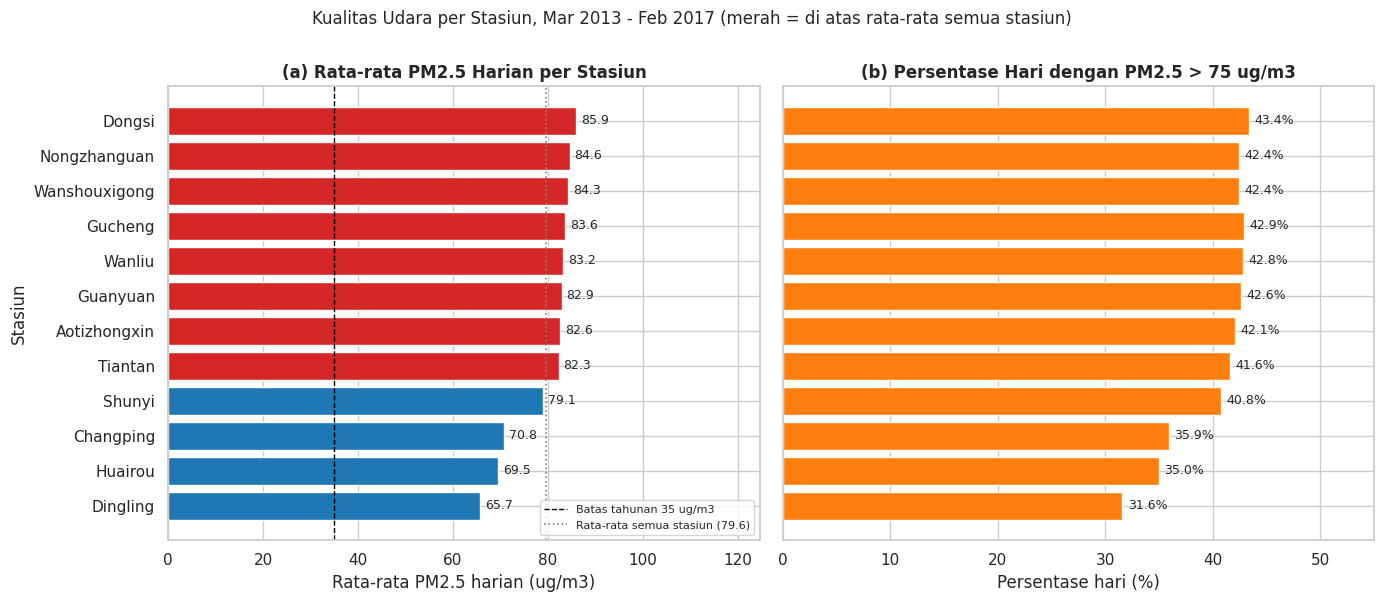

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
order = station_tbl.index
colors = ['#d62728' if v > overall_mean else '#1f77b4' for v in station_tbl['rata2']]
axes[0].barh(order, station_tbl['rata2'], color=colors)
for i, v in enumerate(station_tbl['rata2']):
    axes[0].text(v + 1, i, f'{v:.1f}', va='center', fontsize=9)
axes[0].axvline(35, color='black', linestyle='--', linewidth=1, label='Batas tahunan 35 ug/m3')
axes[0].axvline(overall_mean, color='gray', linestyle=':', linewidth=1.2, label=f'Rata-rata semua stasiun ({overall_mean:.1f})')
axes[0].legend(loc='lower right', fontsize=8)
axes[0].set_title('(a) Rata-rata PM2.5 Harian per Stasiun', fontweight='bold')
axes[0].set_xlabel('Rata-rata PM2.5 harian (ug/m3)')
axes[0].set_ylabel('Stasiun')
axes[0].set_xlim(0, station_tbl['rata2'].max() * 1.45)
axes[0].invert_yaxis()

axes[1].barh(order, station_tbl['hari_di_atas_75_pct'], color='#ff7f0e')
for i, v in enumerate(station_tbl['hari_di_atas_75_pct']):
    axes[1].text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=9)
axes[1].set_title('(b) Persentase Hari dengan PM2.5 > 75 ug/m3', fontweight='bold')
axes[1].set_xlabel('Persentase hari (%)')
axes[1].set_xlim(0, 55)
fig.suptitle('Kualitas Udara per Stasiun, Mar 2013 - Feb 2017 (merah = di atas rata-rata semua stasiun)', fontsize=12, y=1.0)
plt.tight_layout()
plt.show()

### Insight Business Question 1: Perbandingan Kualitas Udara Antar Stasiun

Grafik (a) menunjukkan rata-rata PM2.5 harian tertinggi pada **Dongsi** (85,94 µg/m³) dan terendah pada **Dingling** (65,75 µg/m³), selisih **20,20 µg/m³**. Grafik (b) memperlihatkan persentase hari melampaui 75 µg/m³, dari 31,6% (Dingling) hingga 43,4% (Dongsi). Seluruh stasiun berada jauh di atas batas tahunan 35 µg/m³ (garis putus-putus).

Hal ini menunjukkan perbedaan antarstasiun berupa **dua kelompok**: 9 stasiun yang berdekatan (79,1–85,9 µg/m³) dan 3 stasiun yang lebih bersih (Changping, Huairou, Dingling; 65,7–70,8 µg/m³). Perbedaan di dalam kelompok pertama kecil dan tidak robust (uji sensitivitas membuat stasiun tertinggi berganti).

Temuan ini menjawab pertanyaan bisnis karena menetapkan stasiun terendah (Dingling), selisihnya, dan persentase hari melampaui 75 µg/m³ di tiap stasiun. Pengendalian dan peringatan dini lebih tepat difokuskan pada kelompok 9 stasiun, bukan pada satu stasiun tunggal.

### Visualisasi Business Question 2: Pola Musiman dan Tren Tahunan PM2.5

**Pertanyaan bisnis:** Bagaimana pola bulanan dan musiman rata-rata PM2.5 harian selama 1 Maret 2013 – 28 Februari 2017, bulan dan musim mana yang terburuk, dan bagaimana perubahan rata-rata antar periode tahunan (Maret–Februari), sehingga tim dapat menjadwalkan kesiapsiagaan polusi dan mengevaluasi tren?

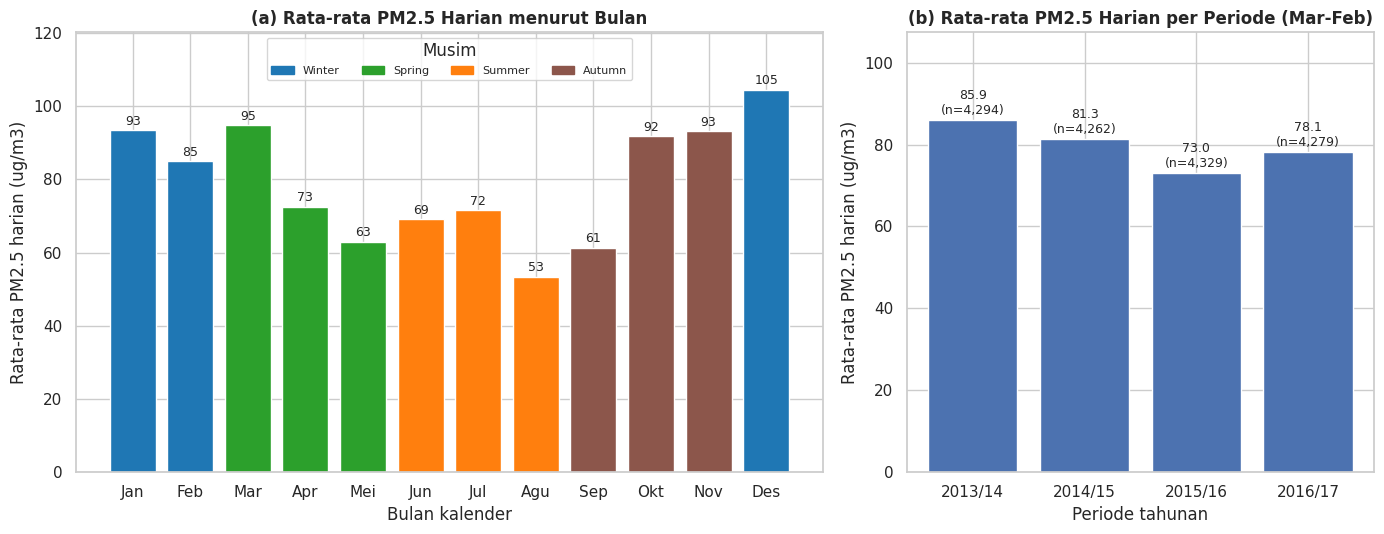

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.6, 1]})
season_colors = {'Winter': '#1f77b4', 'Spring': '#2ca02c', 'Summer': '#ff7f0e', 'Autumn': '#8c564b'}
mcolors = [season_colors[season_map[m]] for m in range(1, 13)]
mt = monthly_tbl.reindex([month_names[m] for m in range(1, 13)])
axes[0].bar(mt.index, mt['rata2'], color=mcolors)
for i, v in enumerate(mt['rata2']):
    axes[0].text(i, v + 1.5, f'{v:.0f}', ha='center', fontsize=9)
axes[0].set_title('(a) Rata-rata PM2.5 Harian menurut Bulan', fontweight='bold')
axes[0].set_xlabel('Bulan kalender')
axes[0].set_ylabel('Rata-rata PM2.5 harian (ug/m3)')
axes[0].set_ylim(0, mt['rata2'].max() * 1.15)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in season_colors.values()]
axes[0].legend(handles, season_colors.keys(), title='Musim', loc='upper center', ncol=4, fontsize=8)

axes[1].bar(period_tbl.index, period_tbl['rata2'], color='#4c72b0')
for i, (v, n) in enumerate(zip(period_tbl['rata2'], period_tbl['hari_valid'])):
    axes[1].text(i, v + 1.5, f'{v:.1f}\n(n={n:,})', ha='center', fontsize=9)
axes[1].set_title('(b) Rata-rata PM2.5 Harian per Periode (Mar-Feb)', fontweight='bold')
axes[1].set_xlabel('Periode tahunan')
axes[1].set_ylabel('Rata-rata PM2.5 harian (ug/m3)')
axes[1].set_ylim(0, period_tbl['rata2'].max() * 1.25)
plt.tight_layout()
plt.show()

### Insight Business Question 2: Pola Musiman dan Tren Tahunan PM2.5

Grafik (a) menunjukkan pola musiman yang jelas: PM2.5 tertinggi pada **Des** (104,5 µg/m³) dan pada bulan-bulan musim dingin dan peralihan (Mar, Jan, Nov), terendah pada **Agu** (53,4 µg/m³). Grafik (b) menunjukkan rata-rata menurun dari 85,9 (2013/14) ke 73,0 (2015/16), lalu naik menjadi 78,1 pada 2016/17.

Hal ini menunjukkan polusi bersifat **musiman** (Winter 94,6 vs Summer 64,6 µg/m³), dan perbaikan antarperiode belum stabil: kenaikan terakhir sebagian besar berasal dari musim dingin (87,1 → 105,2 µg/m³), bukan dari semua musim.

Temuan ini menjawab pertanyaan bisnis karena menetapkan bulan dan musim terburuk, serta arah perubahan antarperiode (-5,4%, -10,2%, lalu +6,9%), sehingga kesiapsiagaan dapat dijadwalkan menjelang musim dingin. Perubahan antarperiode adalah asosiasi dan dapat dipengaruhi cuaca tahunan, bukan bukti efektivitas kebijakan.

### Visualisasi Business Question 3: Pengaruh Kondisi Cuaca (Angin, Hujan, Arah Angin) terhadap PM2.5

**Pertanyaan bisnis:** Bagaimana hubungan kecepatan angin, hujan, dan arah angin dengan PM2.5 harian selama 1 Maret 2013 – 28 Februari 2017, dan berapa persen lebih rendah PM2.5 pada hari berangin (> 3 m/s) dibanding hari tenang (<= 1 m/s), sehingga prakiraan cuaca dapat dipakai untuk peringatan dini polusi?

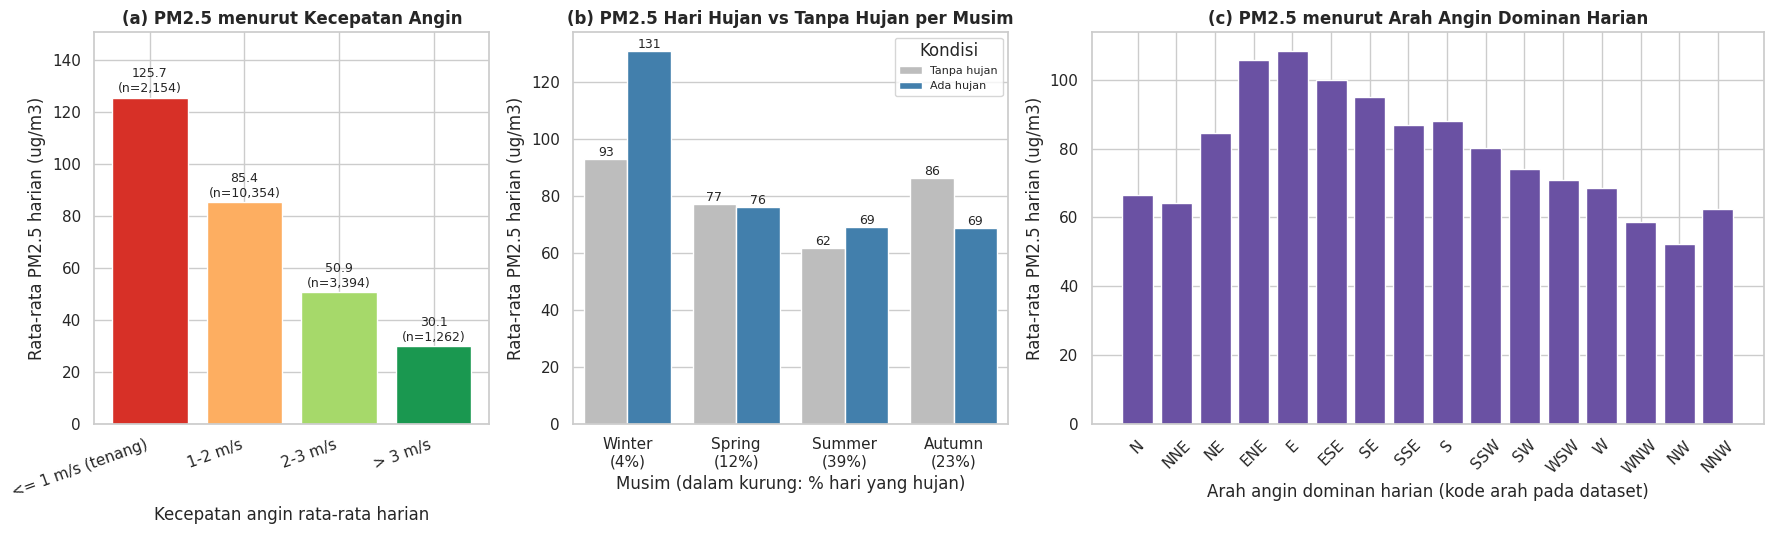

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), gridspec_kw={'width_ratios': [1, 1.1, 1.7]})

b1 = axes[0].bar(wind_tbl.index.astype(str), wind_tbl['rata2'], color=['#d73027', '#fdae61', '#a6d96a', '#1a9850'])
for bar, n in zip(b1, wind_tbl['hari']):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f'{bar.get_height():.1f}\n(n={n:,})', ha='center', fontsize=9)
axes[0].set_title('(a) PM2.5 menurut Kecepatan Angin', fontweight='bold')
axes[0].set_xlabel('Kecepatan angin rata-rata harian')
axes[0].set_ylabel('Rata-rata PM2.5 harian (ug/m3)')
axes[0].set_ylim(0, wind_tbl['rata2'].max() * 1.2)
axes[0].tick_params(axis='x', labelrotation=20)
plt.setp(axes[0].get_xticklabels(), ha='right')

rs = rain_season[['Tanpa hujan', 'Ada hujan']].reset_index().melt(id_vars='season', var_name='Kondisi', value_name='rata2')
sns.barplot(data=rs, x='season', y='rata2', hue='Kondisi', palette=['#bdbdbd', '#3182bd'], ax=axes[1])
for cont in axes[1].containers:
    axes[1].bar_label(cont, fmt='%.0f', fontsize=9)
axes[1].set_xticklabels([f"{s_}\n({rain_share_season[s_]:.0f}%)" for s_ in rain_season.index])
axes[1].set_title('(b) PM2.5 Hari Hujan vs Tanpa Hujan per Musim', fontweight='bold')
axes[1].set_xlabel('Musim (dalam kurung: % hari yang hujan)')
axes[1].set_ylabel('Rata-rata PM2.5 harian (ug/m3)')
axes[1].legend(title='Kondisi', fontsize=8)

dt_ = dir_tbl.reset_index()
axes[2].bar(dt_['wd_dominant'], dt_['rata2'], color='#6a51a3')
axes[2].set_title('(c) PM2.5 menurut Arah Angin Dominan Harian', fontweight='bold')
axes[2].set_xlabel('Arah angin dominan harian (kode arah pada dataset)')
axes[2].set_ylabel('Rata-rata PM2.5 harian (ug/m3)')
axes[2].tick_params(axis='x', labelrotation=45)
plt.tight_layout()
plt.show()

### Insight Business Question 3: Pengaruh Kondisi Cuaca (Angin, Hujan, Arah Angin) terhadap PM2.5

Grafik (a) memperlihatkan PM2.5 turun tajam seiring kecepatan angin: dari **125,7 µg/m³** pada hari tenang menjadi **30,1 µg/m³** pada hari berangin > 3 m/s (**-76,0%**). Grafik (b) menunjukkan pengaruh hujan **tidak konsisten antarmusim** (selisih hari hujan vs tanpa hujan: Winter 40,7%, Autumn -20,2%). Grafik (c) menunjukkan PM2.5 tertinggi saat arah dominan E, ENE, ESE, SE, S dan terendah saat N, NNE, NNW, WNW, NW.

Hal ini menunjukkan **kecepatan angin adalah faktor cuaca yang paling konsisten**: hari tenang (12,5% hari) mengumpulkan polutan, sedangkan angin kencang berasosiasi dengan udara yang jauh lebih bersih. Hujan tidak bisa dipakai sebagai indikator tunggal.

Temuan ini menjawab pertanyaan bisnis karena mengukur selisih PM2.5 pada hari berangin vs tenang (**76,0% lebih rendah**) dan menunjukkan variabel cuaca mana yang layak dipantau untuk peringatan dini (kecepatan dan arah angin). Hubungan ini adalah asosiasi, bukan bukti sebab-akibat.

## Analisis Lanjutan: Manual Grouping Kategori Kualitas Udara Harian (Binning)

### Tujuan Analisis Lanjutan

**Tujuan:** BQ1–BQ3 membandingkan rata-rata, padahal dampak kesehatan dan kebijakan bergantung pada **seberapa sering** udara berada pada tingkat berbahaya. Analisis ini mengelompokkan setiap hari-stasiun ke dalam **kategori kualitas udara** sehingga terlihat proporsi hari bersih hingga hari sangat tercemar, serta bagaimana proporsi itu berbeda menurut stasiun, musim, dan kecepatan angin.

**Metode (bukan machine learning):** *manual grouping/binning* pada rata-rata PM2.5 harian dengan batas kategori mengikuti skema indeks kualitas udara China HJ 633-2012 (rujukan di luar dataset, dipakai sebagai batas domain, bukan hasil perhitungan dari data): **Excellent** (0–35), **Good** (35–75), **Lightly Polluted** (75–115), **Moderately Polluted** (115–150), **Heavily Polluted** (150–250), dan **Severely Polluted** (> 250 µg/m³); batas atas setiap kelas bersifat inklusif. Kategori ini hanya berdasarkan PM2.5, bukan indeks gabungan seluruh polutan.

In [23]:
aqi_overall = daily_valid['aqi_category'].value_counts().reindex(aqi_labels)
aqi_overall_pct = aqi_overall / aqi_overall.sum() * 100
print('Distribusi kategori kualitas udara harian (semua stasiun dan hari):')
display(pd.DataFrame({'hari_stasiun': aqi_overall, 'persen_%': aqi_overall_pct}).round(2))

aqi_station = pd.crosstab(daily_valid['station'], daily_valid['aqi_category'], normalize='index').reindex(columns=aqi_labels) * 100
aqi_station = aqi_station.loc[station_tbl.index]
aqi_season = pd.crosstab(daily_valid['season'], daily_valid['aqi_category'], normalize='index').reindex(columns=aqi_labels) * 100
print('\nKomposisi kategori (%) per musim:')
display(aqi_season.round(1))
print('Komposisi kategori (%) per stasiun (diurutkan dari rata-rata PM2.5 tertinggi):')
display(aqi_station.round(1))

polluted = (daily_valid['pm25_mean'] > 75)
print(f"\nHari-stasiun dengan PM2.5 > 75 (Lightly Polluted atau lebih buruk): {polluted.sum():,} ({polluted.mean():.1%})")
print(f"Hari-stasiun Heavily/Severely Polluted (> 150): {(daily_valid['pm25_mean'] > 150).sum():,} ({(daily_valid['pm25_mean'] > 150).mean():.1%})")
by_wind = pd.crosstab(daily_valid['wind_class'], daily_valid['aqi_category'], normalize='index').reindex(columns=aqi_labels) * 100
print('\nKomposisi kategori (%) menurut kecepatan angin:')
display(by_wind.round(1))

Distribusi kategori kualitas udara harian (semua stasiun dan hari):


,hari_stasiun,persen_%
aqi_category,,
Excellent,5086,29.63
Good,5161,30.07
Lightly Polluted,3133,18.25
Moderately Polluted,1630,9.50
Heavily Polluted,1582,9.22
Severely Polluted,572,3.33



Komposisi kategori (%) per musim:


aqi_category,Excellent,Good,Lightly Polluted,Moderately Polluted,Heavily Polluted,Severely Polluted
season,,,,,,
Winter,31.70,23.10,14.60,10.00,13.40,7.20
Spring,25.90,33.30,20.60,10.10,8.40,1.70
Summer,31.40,34.30,20.40,9.70,4.10,0.20
Autumn,29.70,29.40,17.30,8.20,11.10,4.30


Komposisi kategori (%) per stasiun (diurutkan dari rata-rata PM2.5 tertinggi):


aqi_category,Excellent,Good,Lightly Polluted,Moderately Polluted,Heavily Polluted,Severely Polluted
station,,,,,,
Dongsi,27.60,29.00,18.60,10.60,9.90,4.30
Nongzhanguan,26.90,30.70,18.20,9.70,10.00,4.50
Wanshouxigong,26.30,31.30,18.80,9.90,9.50,4.30
Gucheng,25.50,31.60,19.90,10.00,8.90,4.00
Wanliu,27.30,29.90,19.30,10.30,9.30,3.90
Guanyuan,26.90,30.50,19.60,10.00,9.30,3.60
Aotizhongxin,27.10,30.80,18.20,10.70,9.60,3.70
Tiantan,27.20,31.20,18.30,10.20,9.70,3.40
Shunyi,29.40,29.80,18.60,9.20,10.00,3.00



Hari-stasiun dengan PM2.5 > 75 (Lightly Polluted atau lebih buruk): 6,917 (40.3%)
Hari-stasiun Heavily/Severely Polluted (> 150): 2,154 (12.5%)

Komposisi kategori (%) menurut kecepatan angin:


aqi_category,Excellent,Good,Lightly Polluted,Moderately Polluted,Heavily Polluted,Severely Polluted
wind_class,,,,,,
<= 1 m/s (tenang),11.50,23.40,19.20,12.70,23.20,10.10
1-2 m/s,22.90,32.40,20.60,11.10,9.50,3.40
2-3 m/s,46.40,30.30,15.10,5.60,2.60,0.10
> 3 m/s,70.40,21.70,5.60,1.40,0.90,0.00


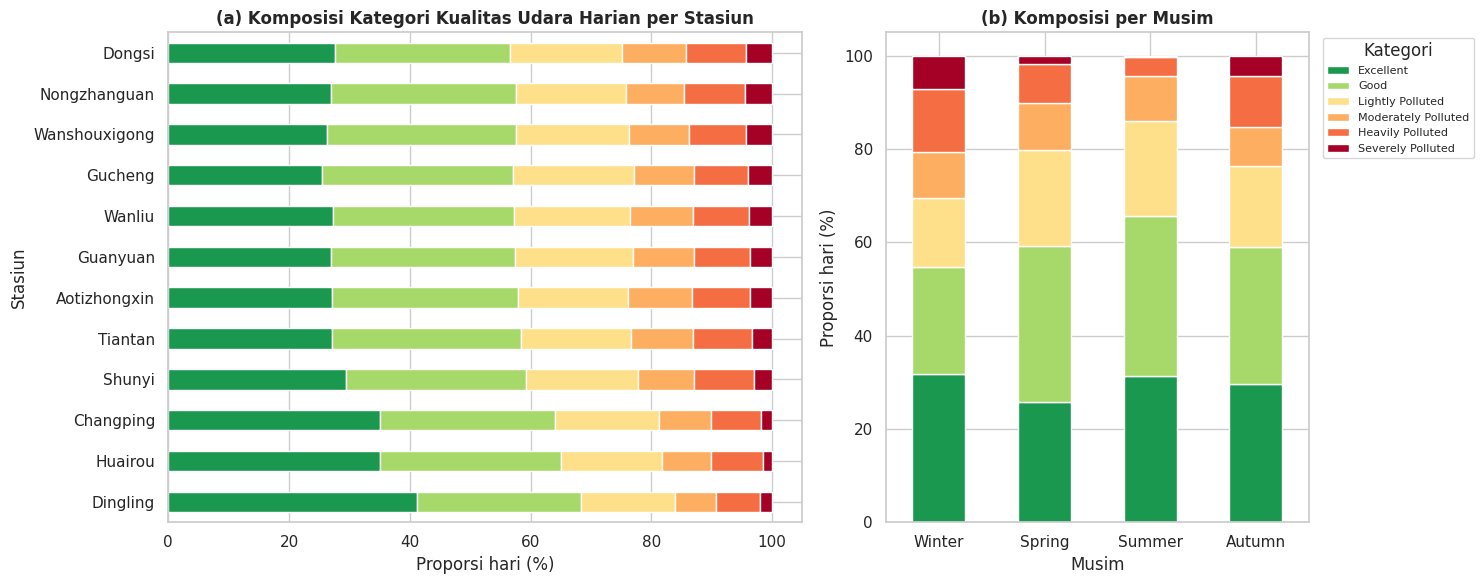

In [24]:
cat_colors = ['#1a9850', '#a6d96a', '#fee08b', '#fdae61', '#f46d43', '#a50026']
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.5, 1]})
aqi_station.plot(kind='barh', stacked=True, color=cat_colors, ax=axes[0], legend=False)
axes[0].set_title('(a) Komposisi Kategori Kualitas Udara Harian per Stasiun', fontweight='bold')
axes[0].set_xlabel('Proporsi hari (%)')
axes[0].set_ylabel('Stasiun')
axes[0].invert_yaxis()
aqi_season.plot(kind='bar', stacked=True, color=cat_colors, ax=axes[1], rot=0)
axes[1].set_title('(b) Komposisi per Musim', fontweight='bold')
axes[1].set_xlabel('Musim')
axes[1].set_ylabel('Proporsi hari (%)')
axes[1].legend(title='Kategori', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

**Insight:**
- Secara keseluruhan hanya **29,6%** hari-stasiun berkategori Excellent dan 30,1% Good; **40,3%** (6.917 hari-stasiun) melampaui 75 µg/m³, dan **12,5%** (2.154 hari-stasiun) Heavily atau Severely Polluted. Hari Severely Polluted (3,3%, 572 hari-stasiun) jarang tetapi nyata.
- **Musim:** pada Winter 20,6% hari Heavily/Severely Polluted (Severely 7,2%), sedangkan Summer hanya 4,3% (Severely 0,2%). Autumn 15,4% dan Spring 10,1%.
- **Stasiun:** hari Excellent 27,6% di Dongsi (rata-rata tertinggi) vs 41,1% di Dingling (terendah); hari Heavily/Severely 14,2% di Dongsi vs 9,3% di Dingling.
- **Angin:** pada hari tenang (<= 1 m/s) 33,3% hari Heavily/Severely Polluted dan hanya 11,5% Excellent; pada hari berangin (> 3 m/s) 0,9% Heavily/Severely dan 70,4% Excellent.
- Musim dingin bersifat **ekstrem ganda**: proporsi hari Excellent-nya (31,7%) sebanding dengan Summer (31,4%), tetapi sekaligus paling banyak hari Heavily/Severely Polluted. Rata-rata saja menyembunyikan variasi ini: musim dingin memiliki hari yang sangat bersih (angin kencang) dan hari yang sangat tercemar (angin lemah).
- Pengelompokan ini menegaskan bahwa risiko tinggi terkonsentrasi pada **musim dingin dan hari tanpa angin**, melengkapi hasil BQ2 dan BQ3.

### Menyimpan data bersih untuk dashboard

**Tujuan:** dashboard Streamlit memakai data yang sama persis dengan notebook sehingga angka dan kategori konsisten. **Struktur:** 1 baris per stasiun per hari valid (hasil agregasi harian).

In [25]:
os.makedirs('dashboard', exist_ok=True)
main_data = daily_valid[['station', 'date', 'month', 'season', 'period', 'pm25_mean', 'pm25_hours', 'wspm_mean', 'rain_mm',
                         'temp_mean', 'wd_dominant', 'aqi_category', 'wind_class', 'rain_day']].copy()
main_data['date'] = main_data['date'].dt.strftime('%Y-%m-%d')
for c in ['season', 'aqi_category', 'wind_class']:
    main_data[c] = main_data[c].astype(str)
for c in ['pm25_mean', 'wspm_mean', 'rain_mm', 'temp_mean']:
    main_data[c] = main_data[c].round(3)
main_data.to_csv('dashboard/main_data.csv', index=False)

print(f'main_data.csv tersimpan: {len(main_data):,} baris (1 baris per stasiun per hari valid) x {main_data.shape[1]} kolom')
print(f"Rata-rata PM2.5 (main_data): {main_data['pm25_mean'].mean():.4f} | notebook: {daily_valid['pm25_mean'].mean():.4f}")

main_data.csv tersimpan: 17,164 baris (1 baris per stasiun per hari valid) x 14 kolom
Rata-rata PM2.5 (main_data): 79.5538 | notebook: 79.5538


## Conclusion & Recommendation

### Conclusion

1. **Business Question 1 (Perbandingan Kualitas Udara Antar Stasiun):** Stasiun pemantau mana yang memiliki rata-rata PM2.5 harian tertinggi dan terendah di antara 12 stasiun selama 1 Maret 2013 – 28 Februari 2017, berapa selisihnya, dan berapa persen hari yang melampaui batas harian 75 µg/m³ di setiap stasiun, sehingga tim pemantau kualitas udara dapat memprioritaskan stasiun/wilayah untuk pengendalian dan peringatan dini?

   **Jawaban:** Rata-rata PM2.5 harian tertinggi pada **Dongsi** (85,94 µg/m³; 43,4% hari di atas 75) dan terendah pada **Dingling** (65,75 µg/m³; 31,6% hari di atas 75), selisih **20,20 µg/m³**. Stasiun terbagi dua kelompok: 9 stasiun pada 79,1–85,9 µg/m³ dan 3 stasiun yang lebih bersih (Changping, Huairou, Dingling; 65,7–70,8). Di dalam kelompok pertama selisihnya kecil dan stasiun tertinggi tidak robust (berganti pada uji sensitivitas). Seluruh stasiun melampaui batas tahunan 35 µg/m³.

2. **Business Question 2 (Pola Musiman dan Tren Tahunan PM2.5):** Bagaimana pola bulanan dan musiman rata-rata PM2.5 harian selama 1 Maret 2013 – 28 Februari 2017, bulan dan musim mana yang terburuk, dan bagaimana perubahan rata-rata antar periode tahunan (Maret–Februari), sehingga tim dapat menjadwalkan kesiapsiagaan polusi dan mengevaluasi tren?

   **Jawaban:** PM2.5 paling tinggi pada **Des** (104,5 µg/m³) dan **Winter** (94,6 µg/m³; 20,6% hari > 150), paling rendah pada **Agu** (53,4) dan Summer (64,6). Rata-rata antarperiode: 2013/14 85,9 → 2014/15 81,3 → 2015/16 73,0 → 2016/17 78,1 µg/m³; periode terakhir naik 6,9% dari sebelumnya, terutama karena musim dingin (87,1 → 105,2).

3. **Business Question 3 (Pengaruh Kondisi Cuaca (Angin, Hujan, Arah Angin) terhadap PM2.5):** Bagaimana hubungan kecepatan angin, hujan, dan arah angin dengan PM2.5 harian selama 1 Maret 2013 – 28 Februari 2017, dan berapa persen lebih rendah PM2.5 pada hari berangin (> 3 m/s) dibanding hari tenang (<= 1 m/s), sehingga prakiraan cuaca dapat dipakai untuk peringatan dini polusi?

   **Jawaban:** PM2.5 **76,0%** lebih rendah pada hari berangin (> 3 m/s; 30,1 µg/m³) dibanding hari tenang (<= 1 m/s; 125,7 µg/m³), dengan penurunan bertahap pada kelas angin di antaranya (korelasi Spearman -0,449). Hujan **tidak konsisten** (selisih hari hujan vs tanpa hujan: Winter 40,7%, Autumn -20,2%). PM2.5 tertinggi saat arah dominan E, ENE, dan ESE, terendah saat NW, WNW, dan NNW. Seluruhnya adalah asosiasi.

4. **Analisis lanjutan (binning):** hanya 29,6% hari-stasiun berkategori Excellent, sedangkan 12,5% Heavily/Severely Polluted. Proporsi hari berat mencapai 20,6% pada Winter (vs 4,3% pada Summer) dan 33,3% pada hari tenang (vs 0,9% pada hari berangin).

**Rekomendasi Action Item** (diturunkan langsung dari temuan di atas):

1. **Fokuskan pengendalian dan peringatan dini pada kelompok 9 stasiun dengan PM2.5 tertinggi (dari BQ1).** Kelompok ini (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng, Wanliu, Guanyuan, Aotizhongxin, Tiantan, Shunyi) berada pada 79,1–85,9 µg/m³ dengan 31,6–43,4% hari di atas 75 µg/m³; karena perbedaan di dalamnya kecil, hindari memilih satu stasiun saja. Jadikan Dingling (65,75 µg/m³) sebagai acuan wilayah yang lebih bersih untuk membandingkan efektivitas intervensi.
2. **Siapkan kesiapsiagaan polusi untuk musim dingin dan bulan Des, Mar, Jan, dan Nov (dari BQ2).** Winter memiliki 20,6% hari Heavily/Severely Polluted dibanding 4,3% pada Summer; rencana tanggap (peringatan publik, pembatasan emisi sementara) sebaiknya aktif sebelum Oktober. Pantau terutama musim dingin, karena kenaikan pada 2016/17 sebagian besar berasal dari sana (87,1 → 105,2 µg/m³).
3. **Gunakan prakiraan angin sebagai sinyal peringatan dini (dari BQ3 dan analisis lanjutan).** Hari tenang (<= 1 m/s; 12,5% hari) memiliki rata-rata 125,7 µg/m³ dan 33,3% hari Heavily/Severely Polluted, versus 30,1 µg/m³ pada hari berangin > 3 m/s. Terbitkan peringatan ketika prakiraan menunjukkan angin lemah berkepanjangan, terutama di musim dingin. Jangan memakai hujan sebagai indikator, karena hubungannya tidak konsisten.
4. **Perbaiki kualitas pengukuran dan pelaporan data (dari Assessing).** Tinjau alat ukur PM2.5/PM10 karena 5,18% baris memiliki PM2.5 > PM10 (terbanyak di Dingling), dan tangani celah data panjang (hingga 343 jam di Aotizhongxin) agar peringkat stasiun tidak bergantung pada baris yang meragukan.

**Catatan keterbatasan:** (a) analisis memakai rata-rata PM2.5 harian dan hanya hari dengan minimal 18 jam valid (368 hari-stasiun dikeluarkan); (b) missing value tidak diimputasi; (c) 21.312 baris PM2.5 > PM10 dipertahankan dan peringkat stasiun teratas tidak robust terhadapnya; (d) hubungan dengan cuaca bersifat asosiasi, bukan sebab-akibat, dan variabel cuaca saling berkaitan; (e) perubahan antarperiode tidak membuktikan efektivitas kebijakan; (f) dataset tidak memuat koordinat sehingga analisis spasial tidak dilakukan; (g) batas 75 µg/m³, 35 µg/m³, dan kategori HJ 633-2012 adalah acuan eksternal, bukan bagian dari dataset.